<a href="https://colab.research.google.com/github/sebastian0412-flz/Estadistica-II/blob/tarea-2/Tarea_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error

# 1. Cargar la base de datos
datos_icfes = pd.read_csv('/content/SB11_20231.TXT', delimiter='¬', engine='python')

# 2. Eliminación de valores faltantes
icfes_sin_nan = datos_icfes[
    (~datos_icfes['ESTU_INSE_INDIVIDUAL'].isna()) &
    (~datos_icfes['PUNT_LECTURA_CRITICA'].isna()) &
    (~datos_icfes['PUNT_MATEMATICAS'].isna()) &
    (~datos_icfes['PUNT_C_NATURALES'].isna()) &
    (~datos_icfes['PUNT_SOCIALES_CIUDADANAS'].isna()) &
    (~datos_icfes['PUNT_INGLES'].isna())
].copy()

print(f"Dimensiones originales: {datos_icfes.shape}")
print(f"Dimensiones sin valores nulos: {icfes_sin_nan.shape}")

Dimensiones originales: (12704, 83)
Dimensiones sin valores nulos: (11853, 83)


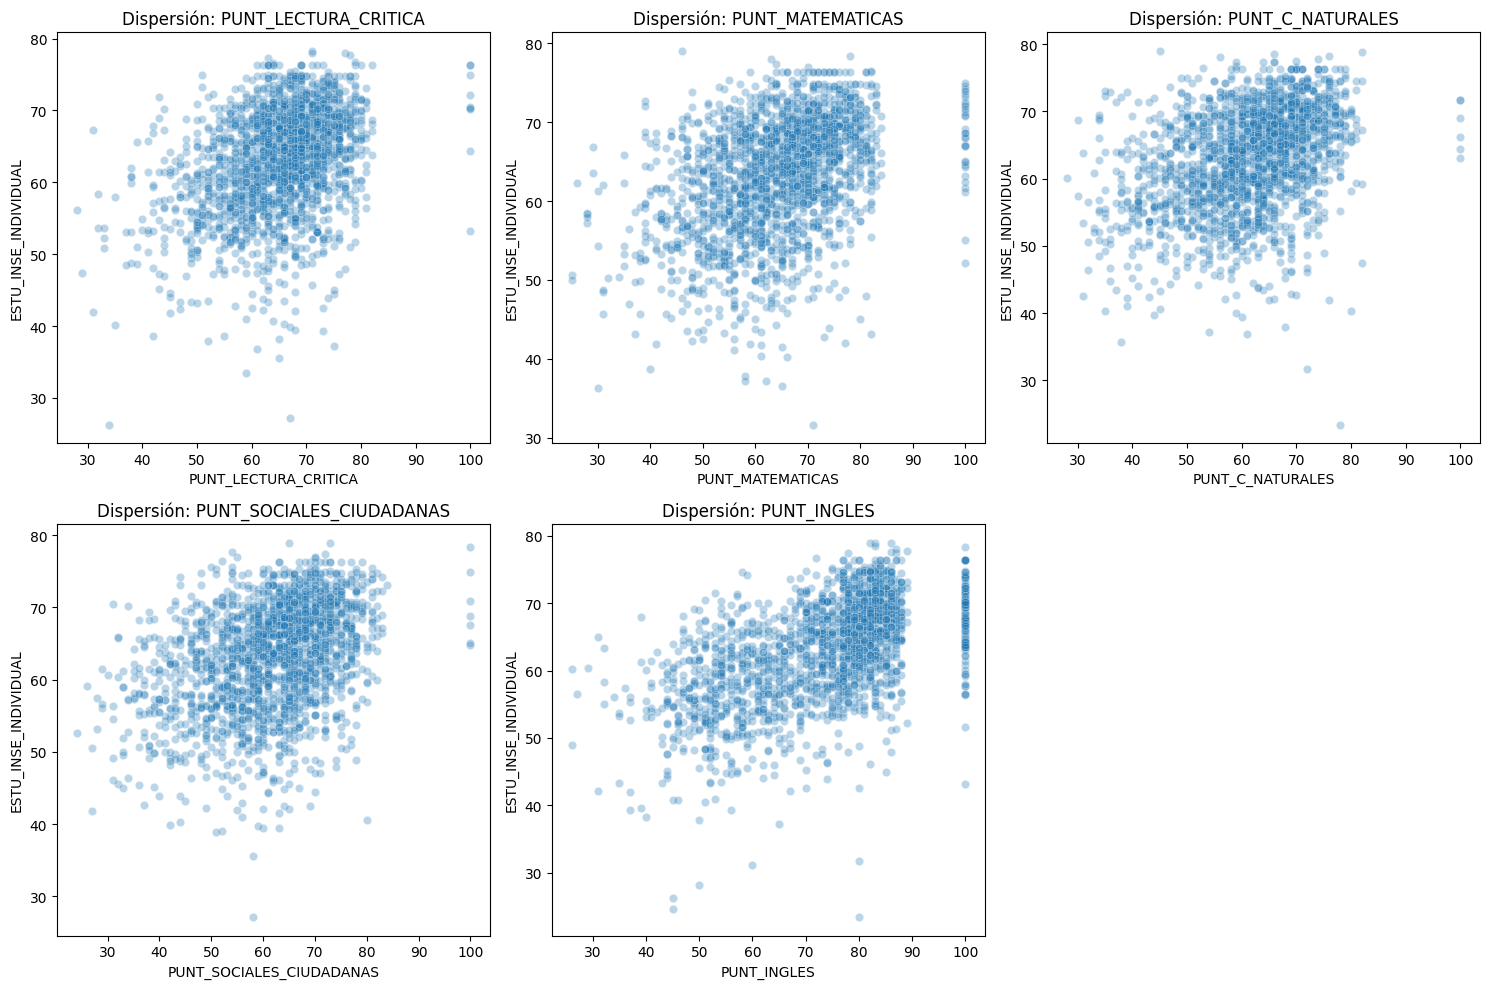

--- Correlación de Pearson ---
PUNT_LECTURA_CRITICA        0.354778
PUNT_MATEMATICAS            0.376665
PUNT_C_NATURALES            0.359855
PUNT_SOCIALES_CIUDADANAS    0.357266
PUNT_INGLES                 0.551155
Name: ESTU_INSE_INDIVIDUAL, dtype: float64

--- Correlación de Spearman ---
PUNT_LECTURA_CRITICA        0.357586
PUNT_MATEMATICAS            0.393935
PUNT_C_NATURALES            0.364746
PUNT_SOCIALES_CIUDADANAS    0.362430
PUNT_INGLES                 0.565737
Name: ESTU_INSE_INDIVIDUAL, dtype: float64

--- Correlación de Kendall (calculada sobre muestra por rendimiento) ---
PUNT_LECTURA_CRITICA        0.240940
PUNT_MATEMATICAS            0.267819
PUNT_C_NATURALES            0.245720
PUNT_SOCIALES_CIUDADANAS    0.243180
PUNT_INGLES                 0.396714
Name: ESTU_INSE_INDIVIDUAL, dtype: float64


In [ ]:
# 3. Selección de variables explicativas mediante correlaciones
variables_exp = ['PUNT_LECTURA_CRITICA', 'PUNT_MATEMATICAS', 'PUNT_C_NATURALES', 'PUNT_SOCIALES_CIUDADANAS', 'PUNT_INGLES']
variable_resp = 'ESTU_INSE_INDIVIDUAL'

# Diagramas de dispersión
plt.figure(figsize=(15, 10))
for i, col in enumerate(variables_exp, 1):
    plt.subplot(2, 3, i)
    sns.scatterplot(data=icfes_sin_nan.sample(min(2000, len(icfes_sin_nan))), x=col, y=variable_resp, alpha=0.3)
    plt.title(f'Dispersión: {col}')
plt.tight_layout()
plt.show()

# Coeficientes de correlación
print("--- Correlación de Pearson ---")
print(icfes_sin_nan[variables_exp + [variable_resp]].corr(method='pearson')[variable_resp].drop(variable_resp))

print("\n--- Correlación de Spearman ---")
print(icfes_sin_nan[variables_exp + [variable_resp]].corr(method='spearman')[variable_resp].drop(variable_resp))

print("\n--- Correlación de Kendall (calculada sobre muestra por rendimiento) ---")
# Kendall suele ser computacionalmente costoso en datasets grandes, usamos muestra si es necesario
print(icfes_sin_nan[variables_exp + [variable_resp]].sample(min(5000, len(icfes_sin_nan))).corr(method='kendall')[variable_resp].drop(variable_resp))

In [ ]:
# 4. Selección por Coeficiente de Determinación (R^2 dejando una fuera)
print("--- Evaluación de R^2 dejando una variable fuera ---")
for var_excluida in variables_exp:
    features = [v for v in variables_exp if v != var_excluida]
    X = icfes_sin_nan[features]
    y = icfes_sin_nan[variable_resp]

    modelo = LinearRegression()
    modelo.fit(X, y)
    r2 = modelo.score(X, y)
    print(f"Modelo sin '{var_excluida}' (usa {features}): R^2 = {r2:.5f}")

# Modelo completo para comparar
X_completo = icfes_sin_nan[variables_exp]
y_completo = icfes_sin_nan[variable_resp]
modelo_completo = LinearRegression().fit(X_completo, y_completo)
print(f"Modelo Completo (todas las variables): R^2 = {modelo_completo.score(X_completo, y_completo):.5f}")

--- Evaluación de R^2 dejando una variable fuera ---
Modelo sin 'PUNT_LECTURA_CRITICA' (usa ['PUNT_MATEMATICAS', 'PUNT_C_NATURALES', 'PUNT_SOCIALES_CIUDADANAS', 'PUNT_INGLES']): R^2 = 0.30559
Modelo sin 'PUNT_MATEMATICAS' (usa ['PUNT_LECTURA_CRITICA', 'PUNT_C_NATURALES', 'PUNT_SOCIALES_CIUDADANAS', 'PUNT_INGLES']): R^2 = 0.30429
Modelo sin 'PUNT_C_NATURALES' (usa ['PUNT_LECTURA_CRITICA', 'PUNT_MATEMATICAS', 'PUNT_SOCIALES_CIUDADANAS', 'PUNT_INGLES']): R^2 = 0.30597
Modelo sin 'PUNT_SOCIALES_CIUDADANAS' (usa ['PUNT_LECTURA_CRITICA', 'PUNT_MATEMATICAS', 'PUNT_C_NATURALES', 'PUNT_INGLES']): R^2 = 0.30598
Modelo sin 'PUNT_INGLES' (usa ['PUNT_LECTURA_CRITICA', 'PUNT_MATEMATICAS', 'PUNT_C_NATURALES', 'PUNT_SOCIALES_CIUDADANAS']): R^2 = 0.16390
Modelo Completo (todas las variables): R^2 = 0.30601


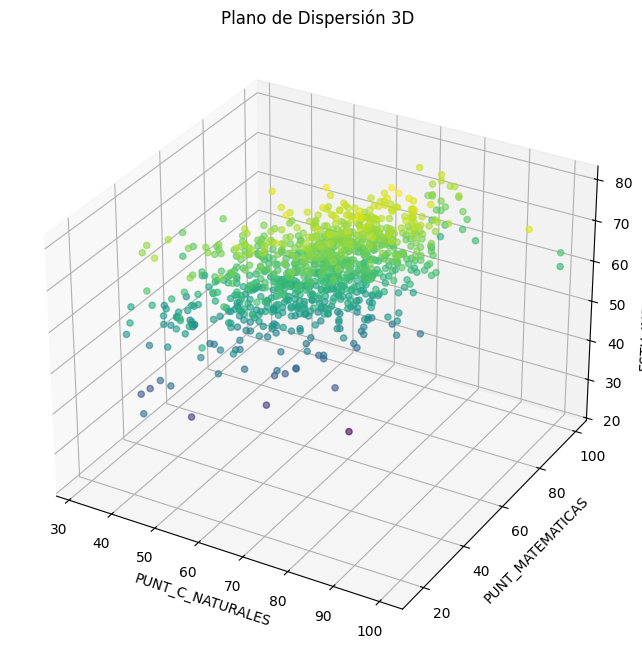

In [ ]:
# 5. Plano de dispersión en 3D con las dos variables más explicativas
# Tomaremos por ejemplo PUNT_C_NATURALES y PUNT_MATEMATICAS (o ajusta según resultados de correlación)
var1, var2 = 'PUNT_C_NATURALES', 'PUNT_MATEMATICAS'

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Tomar muestra pequeña para que el renderizado sea fluido
muestra = icfes_sin_nan.sample(min(1000, len(icfes_sin_nan)))

ax.scatter(muestra[var1], muestra[var2], muestra[variable_resp], c=muestra[variable_resp], cmap='viridis', marker='o', alpha=0.6)
ax.set_xlabel(var1)
ax.set_ylabel(var2)
ax.set_zlabel(variable_resp)
plt.title('Plano de Dispersión 3D')
plt.show()

In [ ]:
# 6. División de datos y entrenamiento de modelos
X = icfes_sin_nan[variables_exp]
y = icfes_sin_nan[variable_resp]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Modelo 1: Regresión Lineal Múltiple
reg_lineal = LinearRegression()
reg_lineal.fit(X_train, y_train)
pred_lineal = reg_lineal.predict(X_test)
r2_lineal = r2_score(y_test, pred_lineal)
rmse_lineal = np.sqrt(mean_squared_error(y_test, pred_lineal))
print(f"Regresión Lineal - R^2 en Test: {r2_lineal:.5f}, RMSE: {rmse_lineal:.5f}")

# Modelo 2: Red Neuronal (MLPRegressor)
red = MLPRegressor(hidden_layer_sizes=(100, 100, 100, 100, 100, 100),
                   max_iter=500,
                   activation='relu',
                   solver='adam',
                   learning_rate='invscaling',
                   random_state=42)

red.fit(X_train, y_train)
pred_red = red.predict(X_test)
r2_red = r2_score(y_test, pred_red)
rmse_red = np.sqrt(mean_squared_error(y_test, pred_red))
print(f"Red Neuronal MLP - R^2 en Test: {r2_red:.5f}, RMSE: {rmse_red:.5f}")

Regresión Lineal - R^2 en Test: 0.31981, RMSE: 6.12357
Red Neuronal MLP - R^2 en Test: 0.29764, RMSE: 6.22254


In [ ]:
# 7. Imputación utilizando el mejor modelo
# Identificar filas a imputar (donde ESTU_INSE_INDIVIDUAL es nulo pero tenemos las explicativas)
filas_faltantes = datos_icfes[
    (datos_icfes['ESTU_INSE_INDIVIDUAL'].isna()) &
    (~datos_icfes['PUNT_LECTURA_CRITICA'].isna()) &
    (~datos_icfes['PUNT_MATEMATICAS'].isna()) &
    (~datos_icfes['PUNT_C_NATURALES'].isna()) &
    (~datos_icfes['PUNT_SOCIALES_CIUDADANAS'].isna()) &
    (~datos_icfes['PUNT_INGLES'].isna())
].copy()

if len(filas_faltantes) > 0:
    X_imputar = filas_faltantes[variables_exp]
    # Seleccionar el mejor modelo basado en R^2 de prueba
    if r2_red > r2_lineal:
        mejor_modelo = red
        print("Imputando con la Red Neuronal (Mejor ajuste)... ")
    else:
        mejor_modelo = reg_lineal
        print("Imputando con la Regresión Lineal (Mejor ajuste)... ")

    valores_imputados = mejor_modelo.predict(X_imputar)
    datos_icfes.loc[filas_faltantes.index, 'ESTU_INSE_INDIVIDUAL'] = valores_imputados
    print(f"Se imputaron con éxito {len(valores_imputados)} valores nulos de 'ESTU_INSE_INDIVIDUAL'.")
else:
    print("No se encontraron filas con datos nulos aptas para imputación (que tengan todas las variables explicativas presentes).")

Imputando con la Regresión Lineal (Mejor ajuste)... 
Se imputaron con éxito 849 valores nulos de 'ESTU_INSE_INDIVIDUAL'.
